<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

# Synthetic Financial Time Series

**GAN-based Generation of Realistic Return Data (PyTorch)**

&copy; Dr. Yves J. Hilpisch

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>

## Imports & Settings

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pylab import plt, mpl

In [2]:
import torch
from torch import nn

In [3]:
sys.path.insert(0, os.path.abspath('..'))
from synthts.data import load_eod, compute_log_returns, ReturnScaler
from synthts.models import Generator, Discriminator, GAN
from synthts.train import train_gan, generate_samples
from synthts.evaluate import (ks_test, ks_test_batch, pass_rate,
    describe_comparison, mse_sorted,
    plot_real_vs_synth, plot_histograms, plot_sorted,
    plot_cumulative, plot_pvalue_histogram)

In [4]:
plt.style.use('seaborn-v0_8')
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'serif'

## Simple Example — Learning a Cubic Function

In [5]:
x = np.linspace(-2, 2, 500)
y = x ** 3

In [6]:
scaler = ReturnScaler()
y_ = scaler.fit_transform(y)

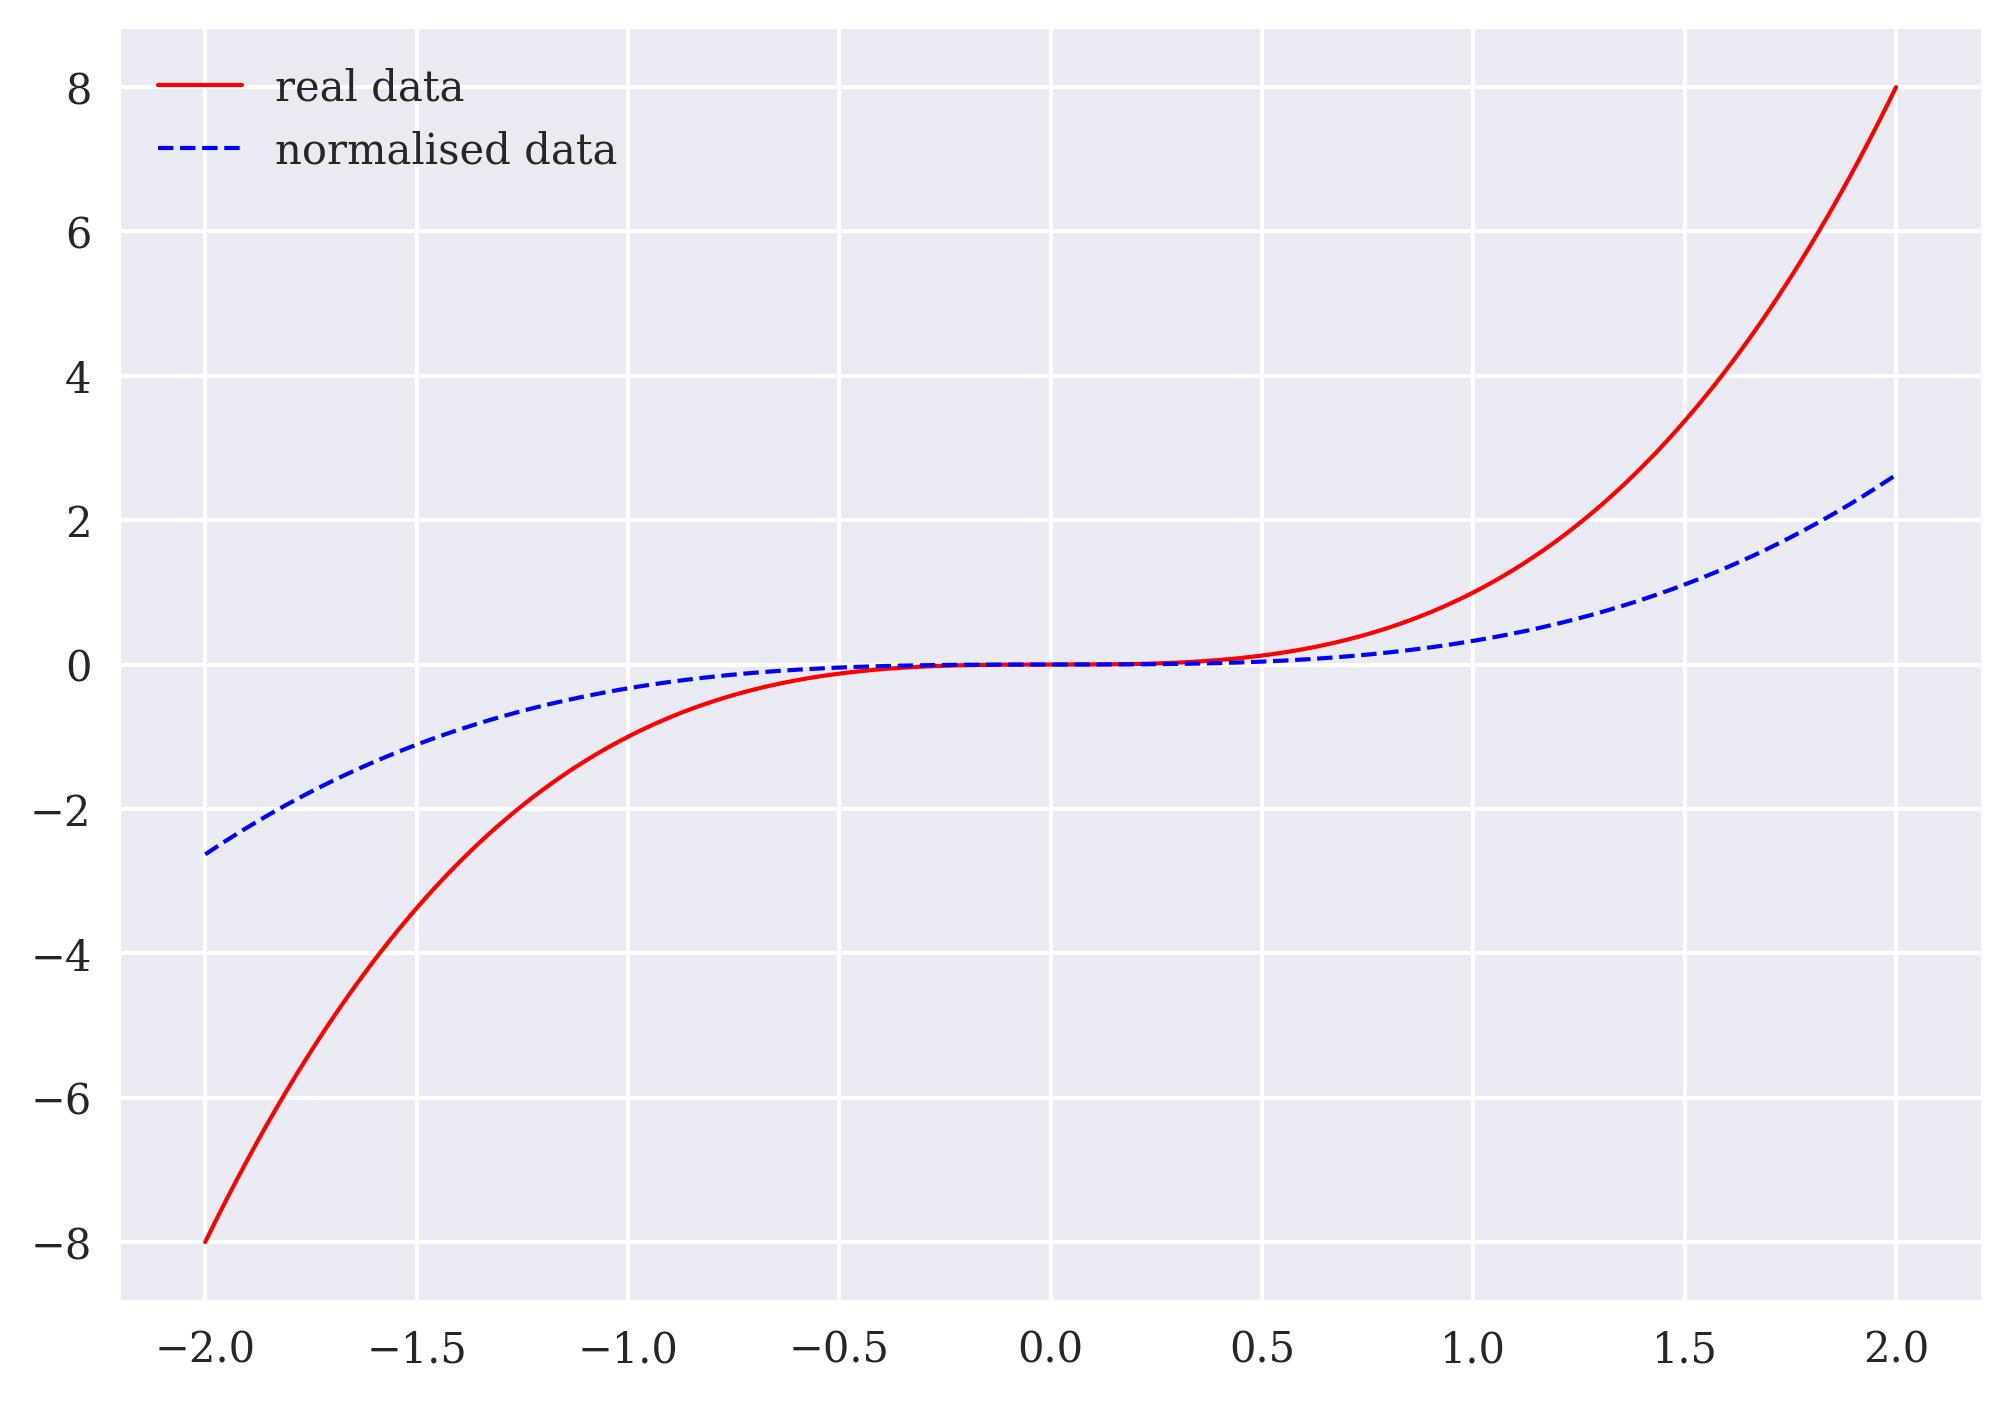

In [7]:
plt.plot(x, y, 'r', lw=1.0, label='real data')
plt.plot(x, y_, 'b--', lw=1.0, label='normalised data')
plt.legend();

### Model Training

In [8]:
generator = Generator(latent_dim=1, hidden_units=32, output_dim=1)
discriminator = Discriminator(input_dim=1, hidden_units=32)

In [9]:
%%time
history = train_gan(
    generator, discriminator, y_.reshape(-1, 1),
    epochs=15001, batch_size=32,
    lr_d=0.001, lr_g=0.0001, seed=100
)

Epoch     0 | D_real: 0.7710 D_fake: 0.6431 G: 0.7383
Epoch  1000 | D_real: 0.6779 D_fake: 0.7115 G: 0.7720
Epoch  2000 | D_real: 0.6847 D_fake: 0.6993 G: 0.6944
Epoch  3000 | D_real: 0.6779 D_fake: 0.6802 G: 0.6971
Epoch  4000 | D_real: 0.6999 D_fake: 0.6713 G: 0.7753
Epoch  5000 | D_real: 0.6699 D_fake: 0.6918 G: 0.7004
Epoch  6000 | D_real: 0.6934 D_fake: 0.6697 G: 0.7388
Epoch  7000 | D_real: 0.6869 D_fake: 0.6741 G: 0.7049
Epoch  8000 | D_real: 0.7156 D_fake: 0.6508 G: 0.7521
Epoch  9000 | D_real: 0.7081 D_fake: 0.6935 G: 0.7162
Epoch 10000 | D_real: 0.6683 D_fake: 0.7241 G: 0.6983
Epoch 11000 | D_real: 0.6866 D_fake: 0.7005 G: 0.6976
Epoch 12000 | D_real: 0.7056 D_fake: 0.7003 G: 0.7146
Epoch 13000 | D_real: 0.6638 D_fake: 0.7102 G: 0.6903
Epoch 14000 | D_real: 0.6910 D_fake: 0.6840 G: 0.6967
Epoch 15000 | D_real: 0.7076 D_fake: 0.6840 G: 0.6944
CPU times: user 6.17 s, sys: 73.1 ms, total: 6.24 s
Wall time: 6.38 s


### Evaluation

In [10]:
data = pd.DataFrame({'real': y}, index=x)
N = 5
for i in range(N):
    samples = generate_samples(generator, len(y), latent_dim=1)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [11]:
data.describe().round(3)

,real,synth_00,synth_01,synth_02,synth_03,synth_04
count,500.000,500.000,500.000,500.000,500.000,500.000
mean,-0.000,0.694,0.455,0.507,0.502,0.573
std,3.045,3.126,3.066,3.099,2.971,3.256
min,-8.000,-7.829,-9.389,-7.770,-8.348,-8.228
25%,-1.000,-0.178,-0.880,-0.726,-0.332,-0.708
50%,-0.000,0.185,0.184,0.182,0.180,0.182
75%,1.000,1.949,1.566,1.597,1.358,1.539
max,8.000,8.895,8.432,9.004,8.393,9.525


In [12]:
mse_sorted(data['real'].values, data['synth_00'].values)

np.float64(0.6410780424903878)

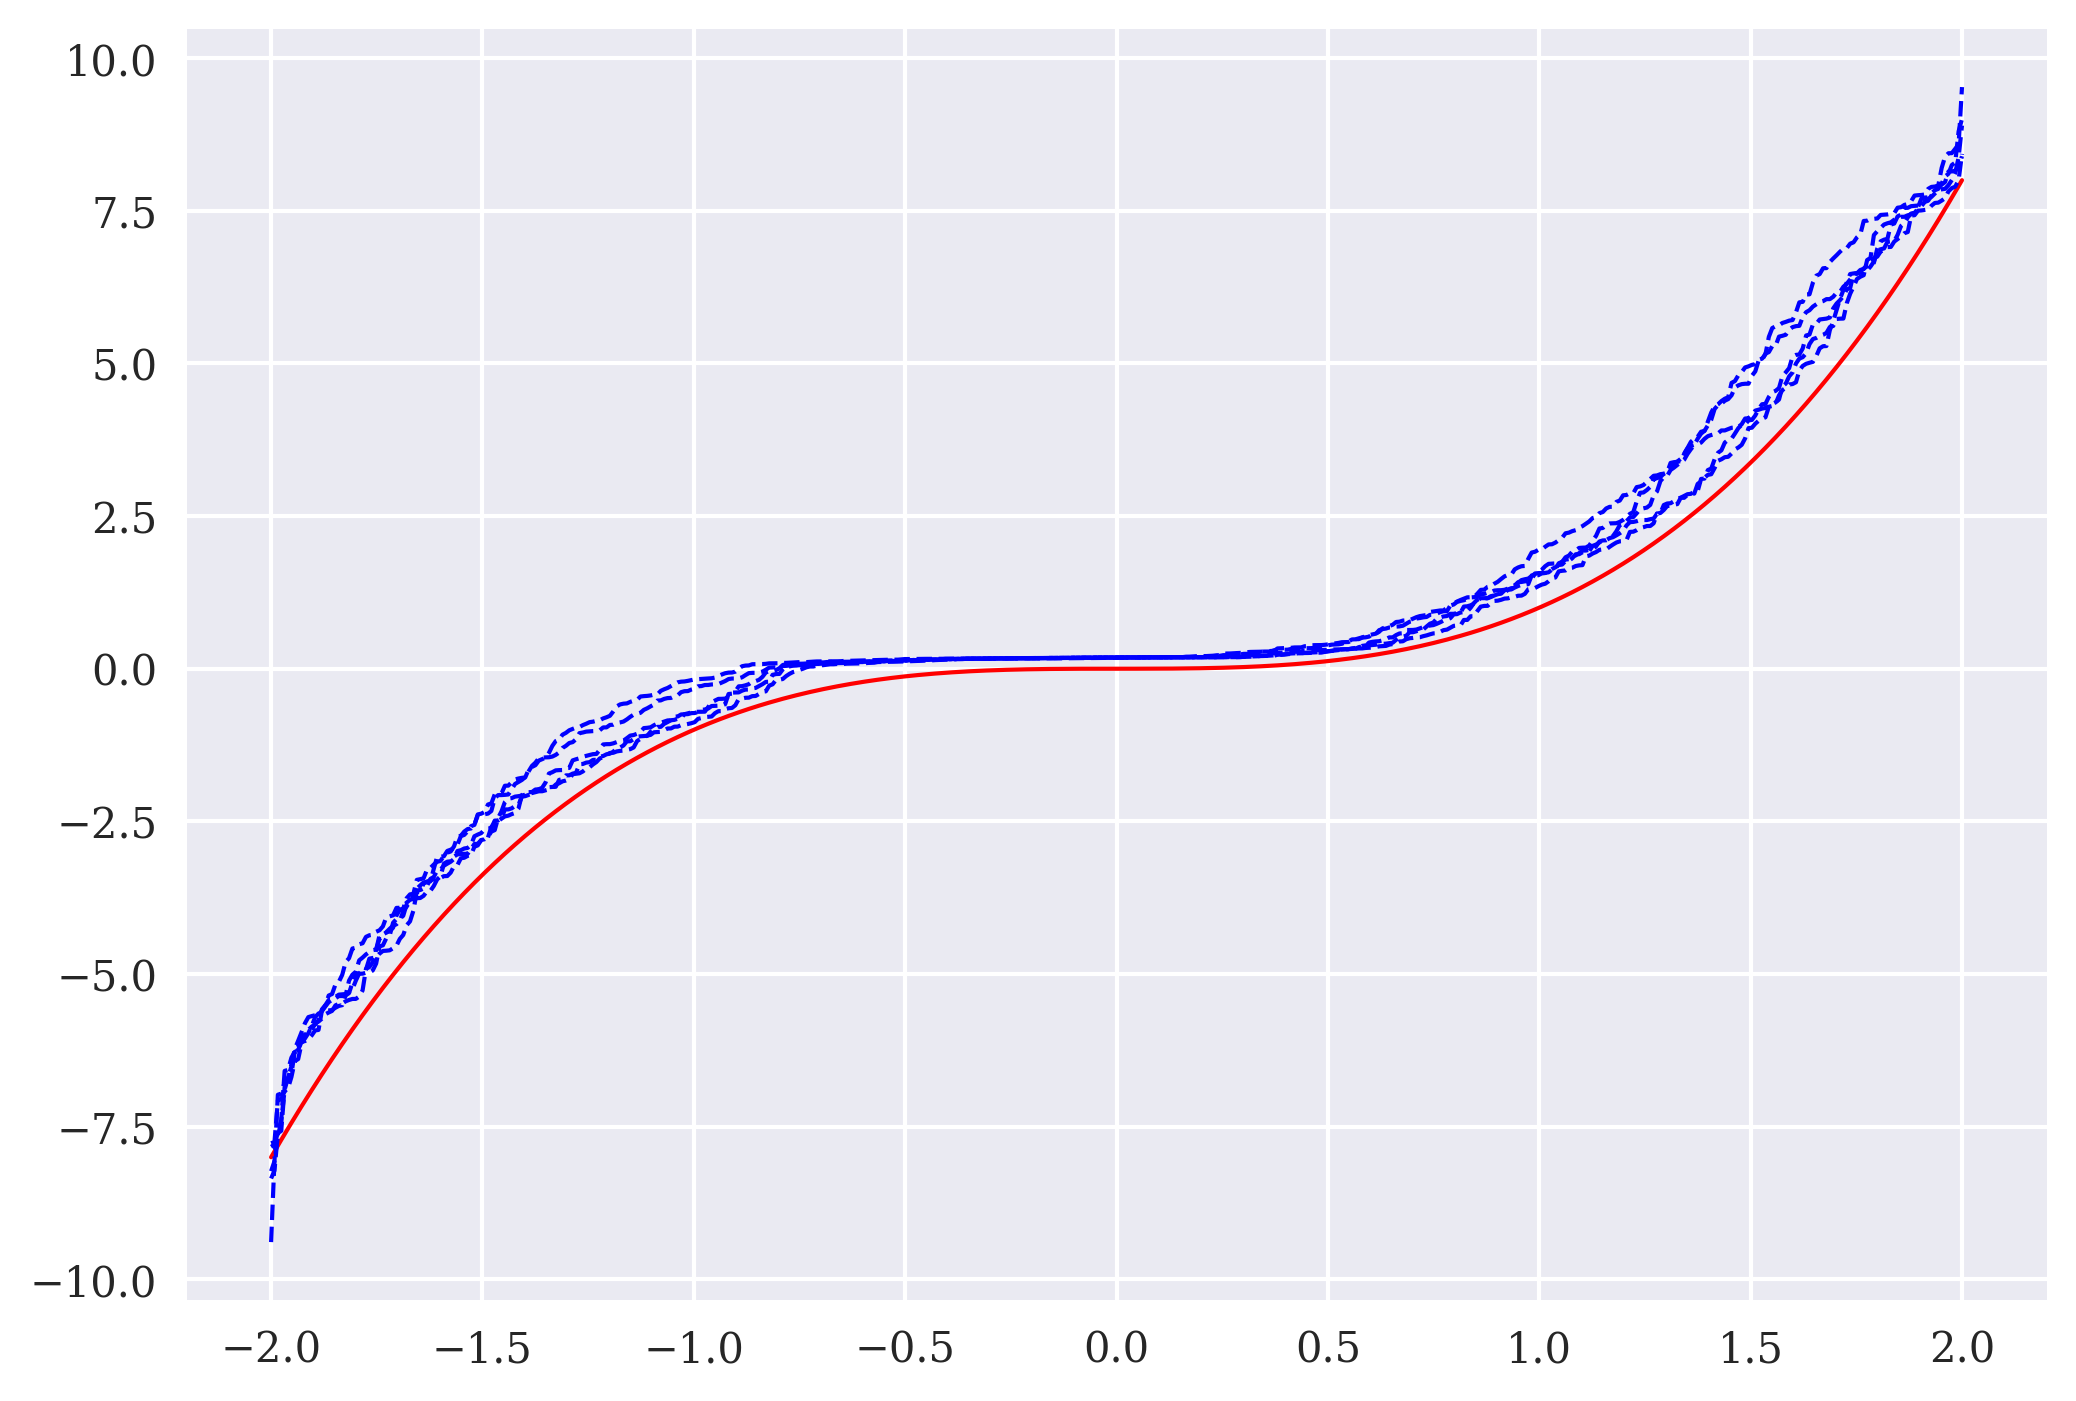

In [13]:
data.apply(np.sort).plot(
    style=['r'] + N * ['b--'], lw=1, legend=False);

## Financial Example — Real Log-Returns

In [81]:
SYM = 'SPY'

In [82]:
prices = load_eod(symbol=SYM, n_obs=2 * 252)
rets = compute_log_returns(prices)

In [83]:
scaler = ReturnScaler()
rets_ = scaler.fit_transform(rets)

In [84]:
generator = Generator(latent_dim=1, hidden_units=16, output_dim=1)
discriminator = Discriminator(input_dim=1, hidden_units=16)

In [85]:
%%time
history = train_gan(
    generator, discriminator, rets_.reshape(-1, 1),
    epochs=15001, batch_size=32,
    lr_d=0.001, lr_g=0.0001, seed=100
)

Epoch     0 | D_real: 0.7194 D_fake: 0.6697 G: 0.7167
Epoch  1000 | D_real: 0.6801 D_fake: 0.6837 G: 0.7337
Epoch  2000 | D_real: 0.6417 D_fake: 0.6605 G: 0.6849
Epoch  3000 | D_real: 0.7096 D_fake: 0.6740 G: 0.7182
Epoch  4000 | D_real: 0.7139 D_fake: 0.6750 G: 0.6971
Epoch  5000 | D_real: 0.6948 D_fake: 0.6832 G: 0.7018
Epoch  6000 | D_real: 0.6999 D_fake: 0.6811 G: 0.6978
Epoch  7000 | D_real: 0.6973 D_fake: 0.6843 G: 0.7135
Epoch  8000 | D_real: 0.6987 D_fake: 0.6758 G: 0.6945
Epoch  9000 | D_real: 0.6962 D_fake: 0.6894 G: 0.6878
Epoch 10000 | D_real: 0.7099 D_fake: 0.6828 G: 0.7222
Epoch 11000 | D_real: 0.6870 D_fake: 0.6968 G: 0.6867
Epoch 12000 | D_real: 0.6898 D_fake: 0.6995 G: 0.6936
Epoch 13000 | D_real: 0.6976 D_fake: 0.6770 G: 0.7053
Epoch 14000 | D_real: 0.6759 D_fake: 0.7045 G: 0.6864
Epoch 15000 | D_real: 0.7009 D_fake: 0.6833 G: 0.7051
CPU times: user 5.88 s, sys: 11.8 ms, total: 5.89 s
Wall time: 5.89 s


### Generating Synthetic Returns

In [86]:
data = pd.DataFrame({'real': rets})
N = 25
for i in range(N):
    samples = generate_samples(generator, len(rets_), latent_dim=1)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [87]:
describe_comparison(data, n_show=5)

,real,synth_00,synth_01,synth_02,synth_03
count,503.0000,503.0000,503.0000,503.0000,503.0000
mean,0.0008,0.0010,0.0000,0.0004,0.0010
std,0.0102,0.0085,0.0085,0.0089,0.0087
min,-0.0603,-0.0321,-0.0422,-0.0398,-0.0329
25%,-0.0031,-0.0028,-0.0044,-0.0040,-0.0028
50%,0.0011,0.0014,0.0008,0.0011,0.0007
75%,0.0057,0.0058,0.0051,0.0057,0.0057
max,0.0999,0.0306,0.0258,0.0335,0.0268


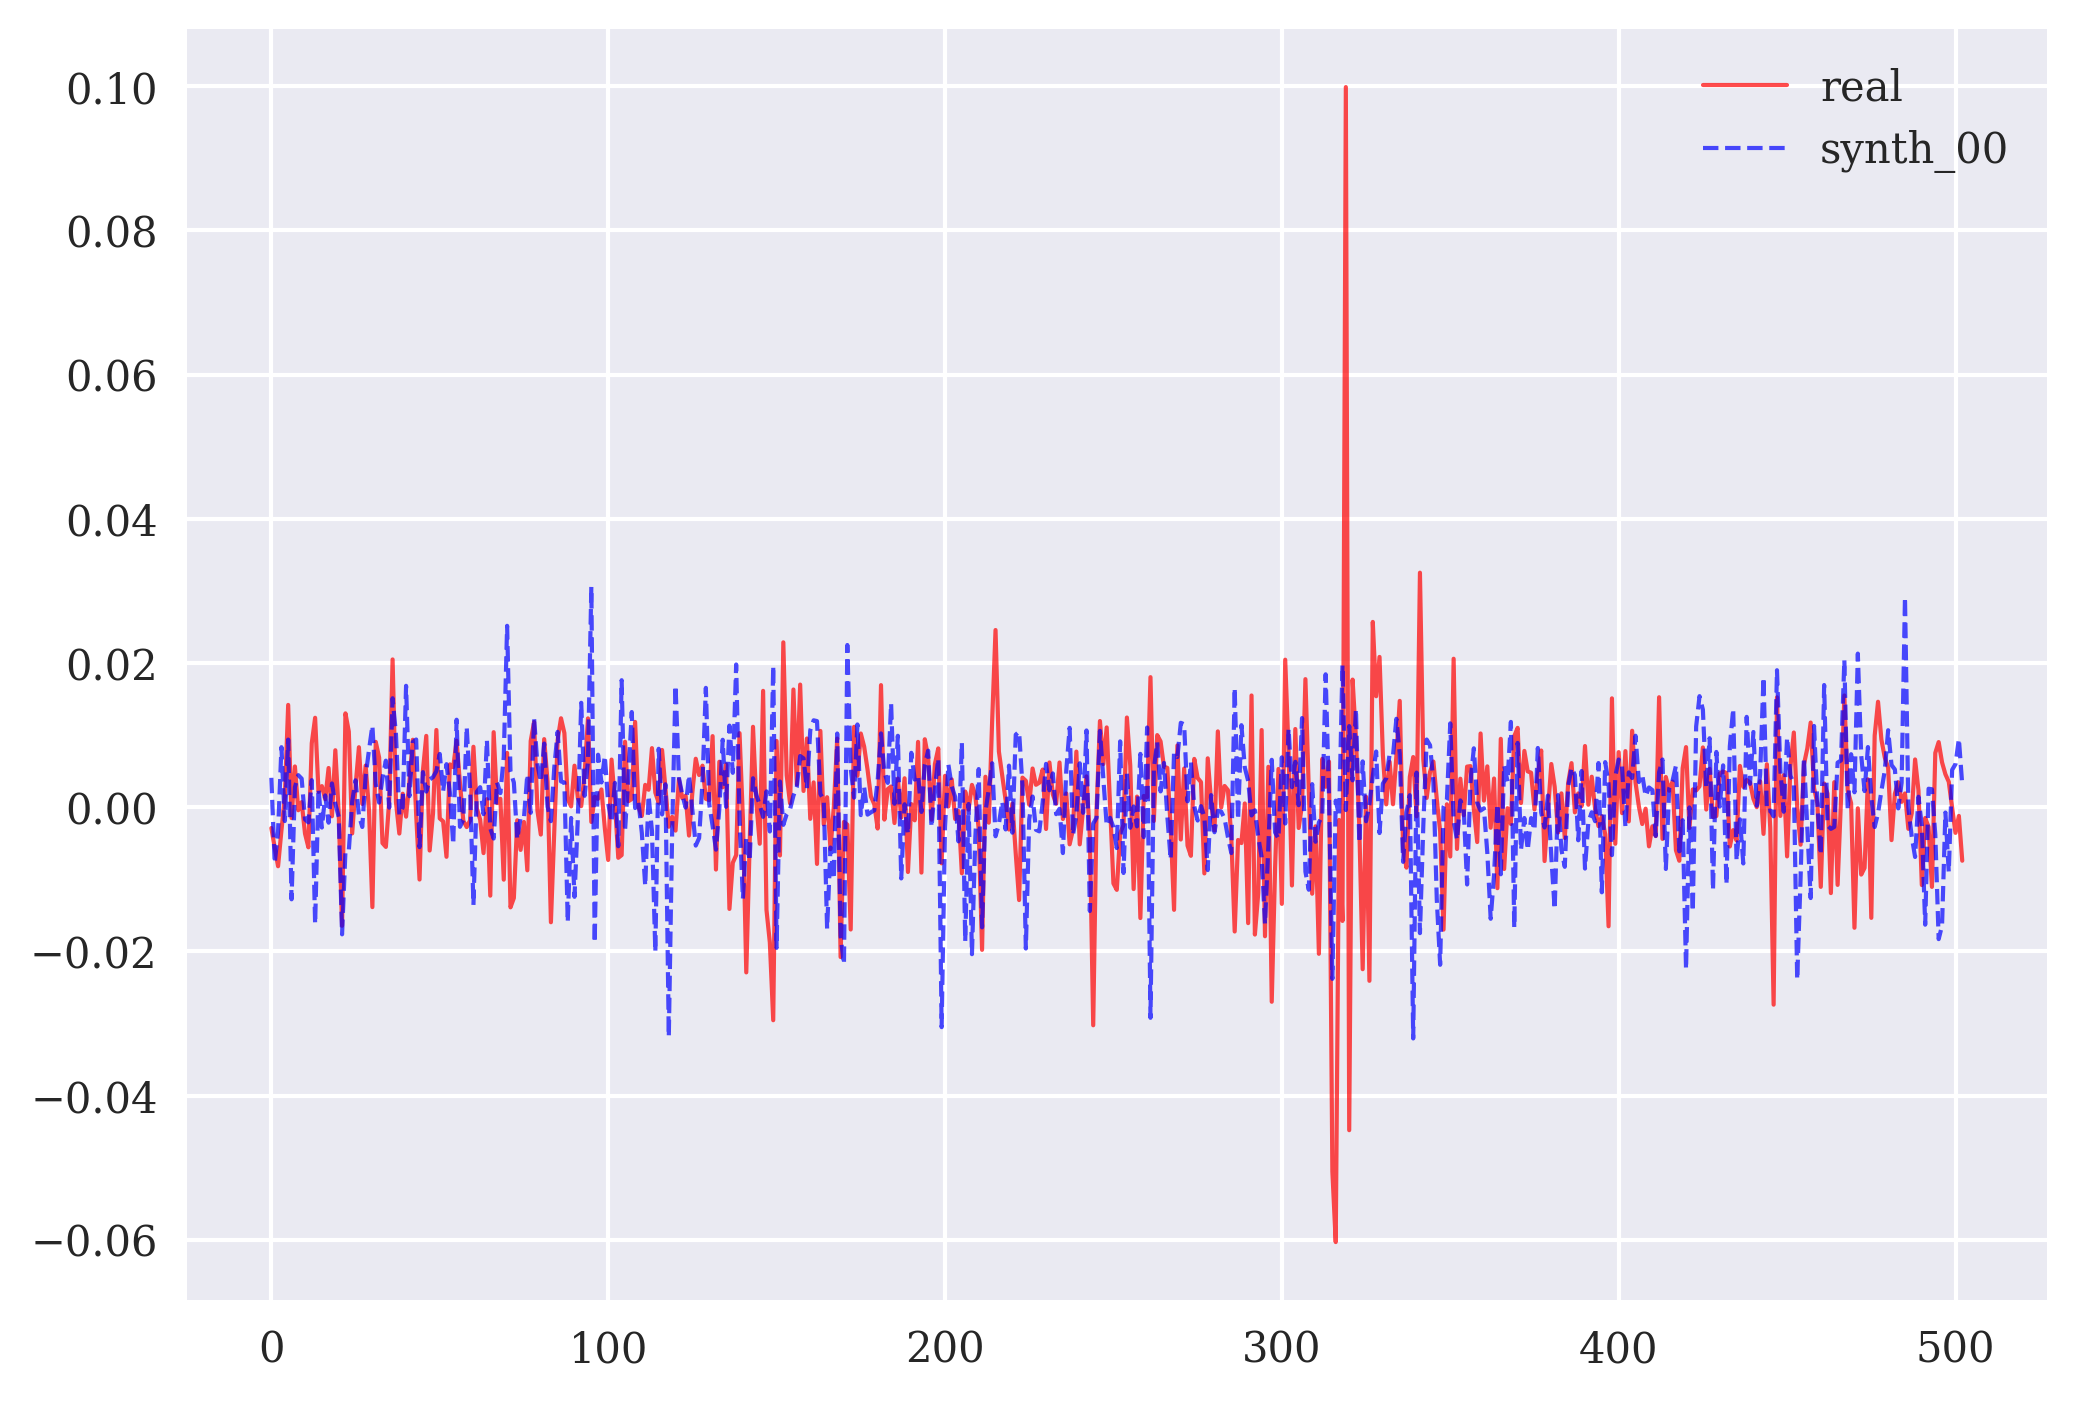

In [88]:
plot_real_vs_synth(data, n_synth=1);

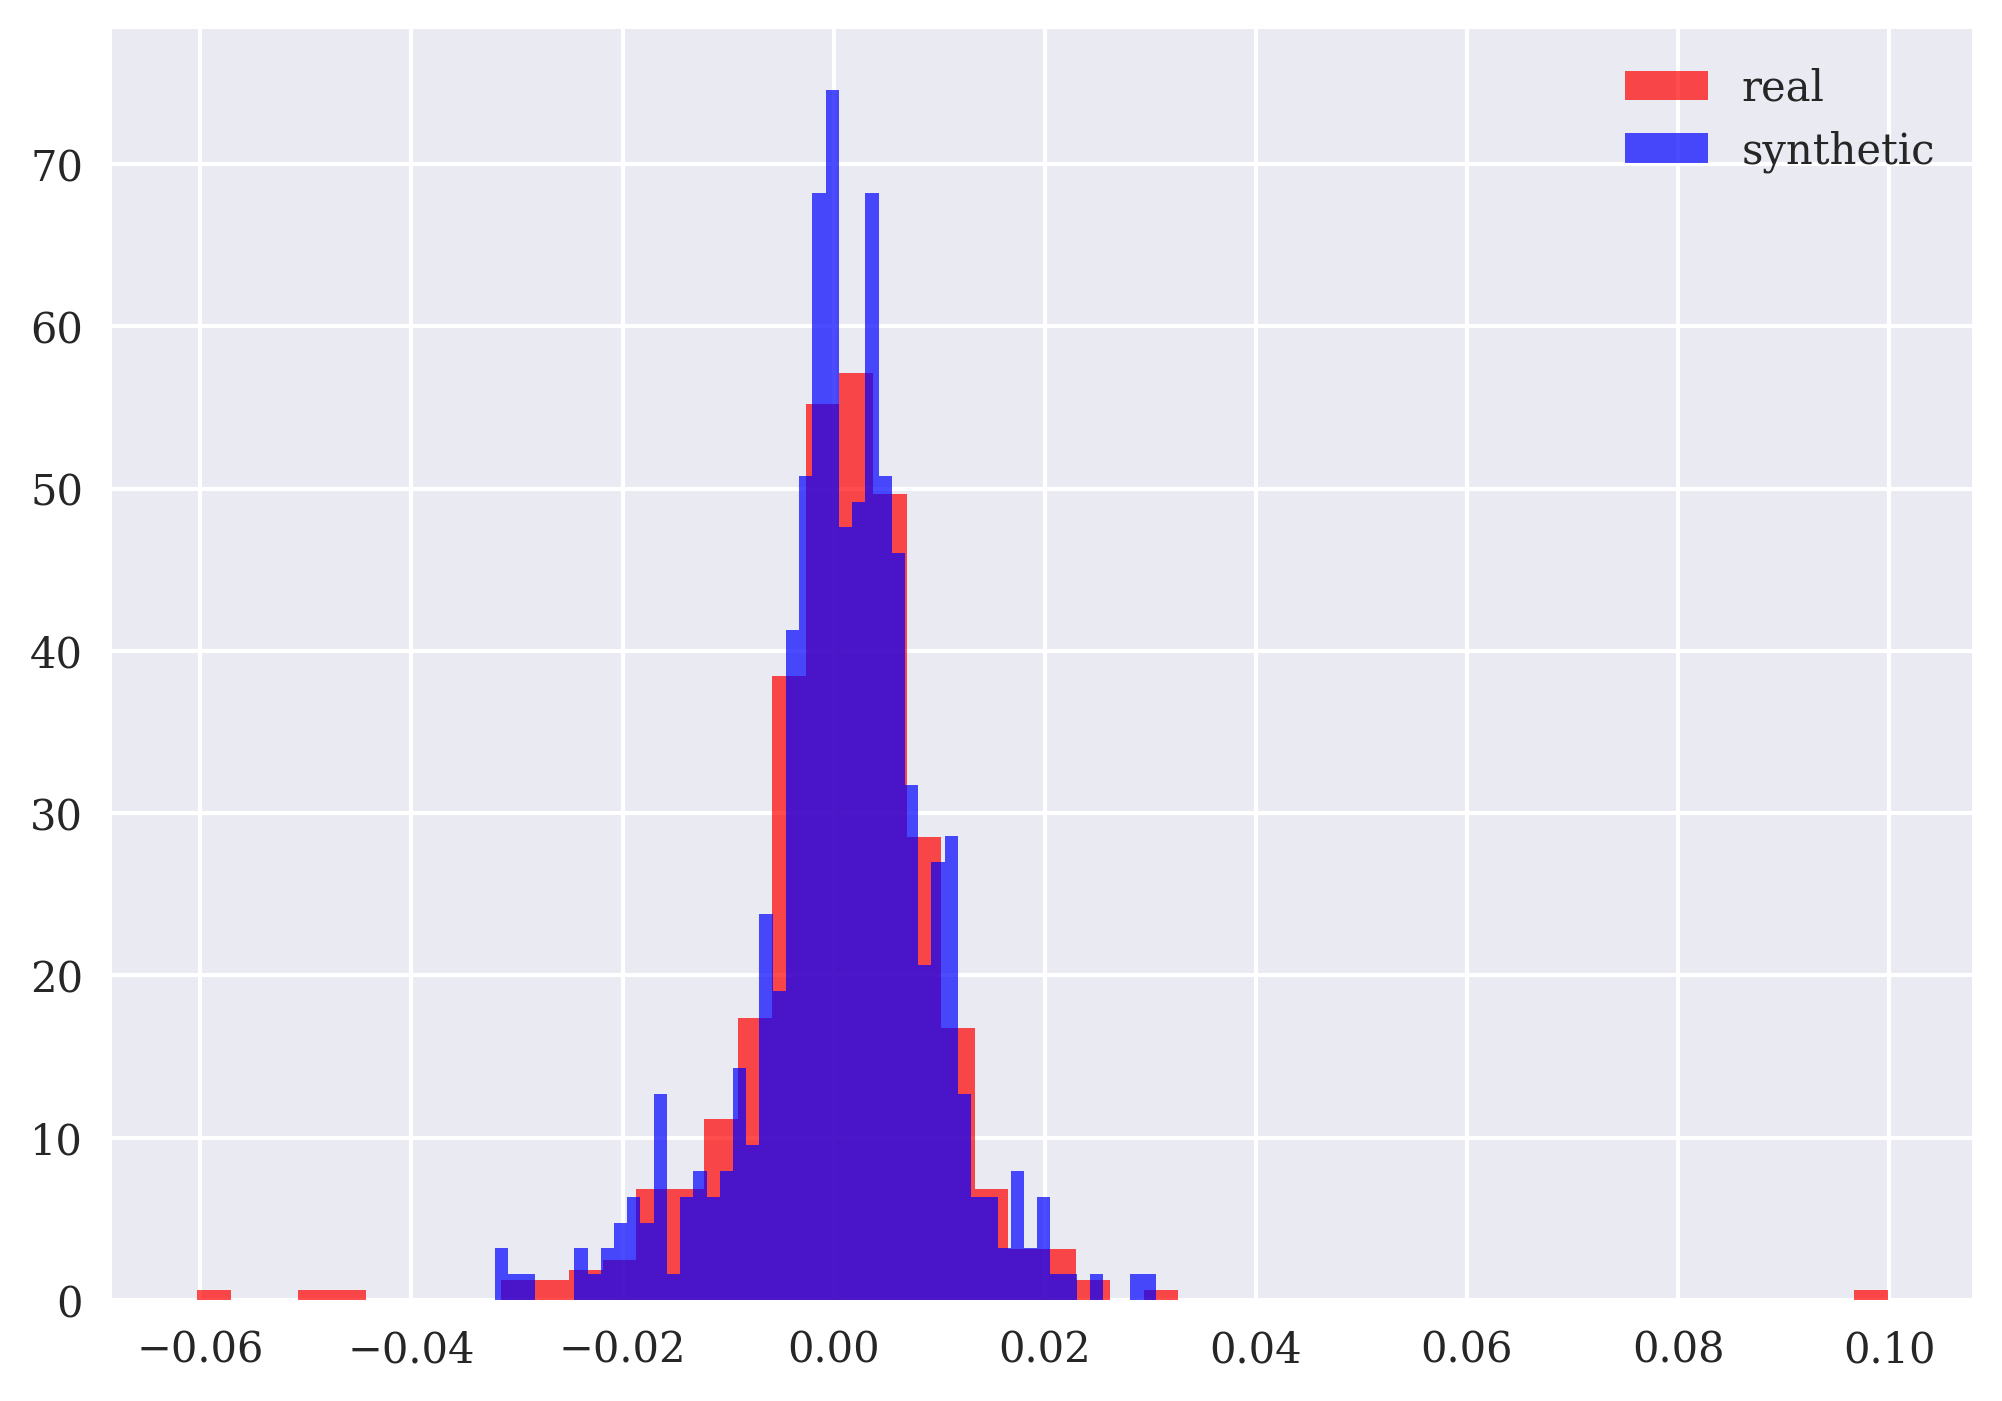

In [89]:
plot_histograms(data['real'].values, data['synth_00'].values);

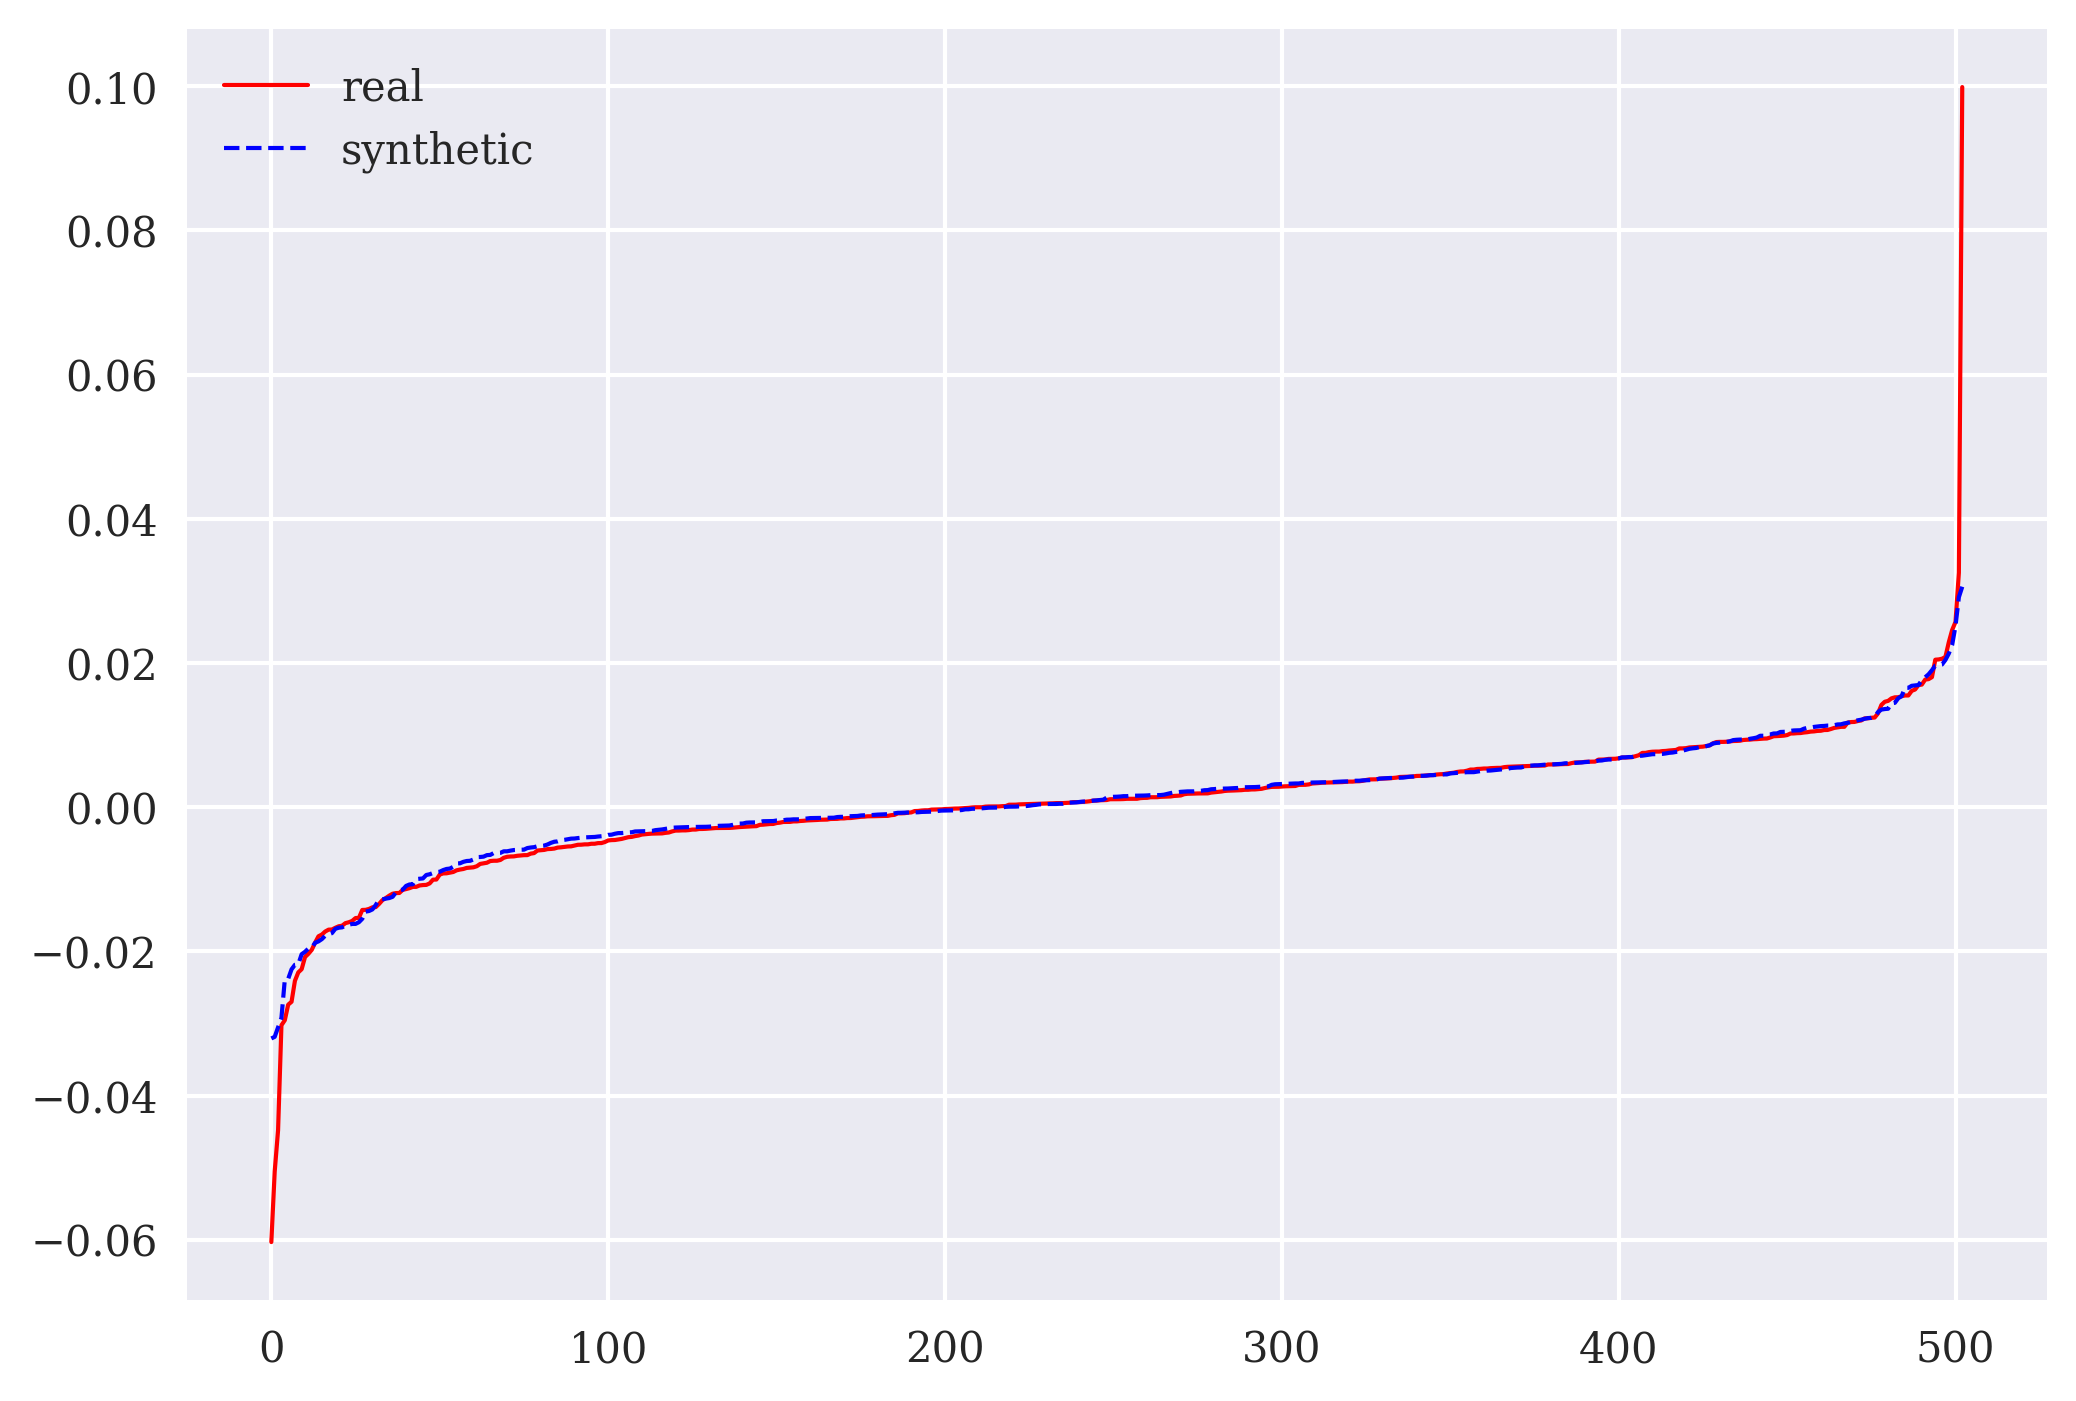

In [90]:
plot_sorted(data['real'].values, data['synth_00'].values);

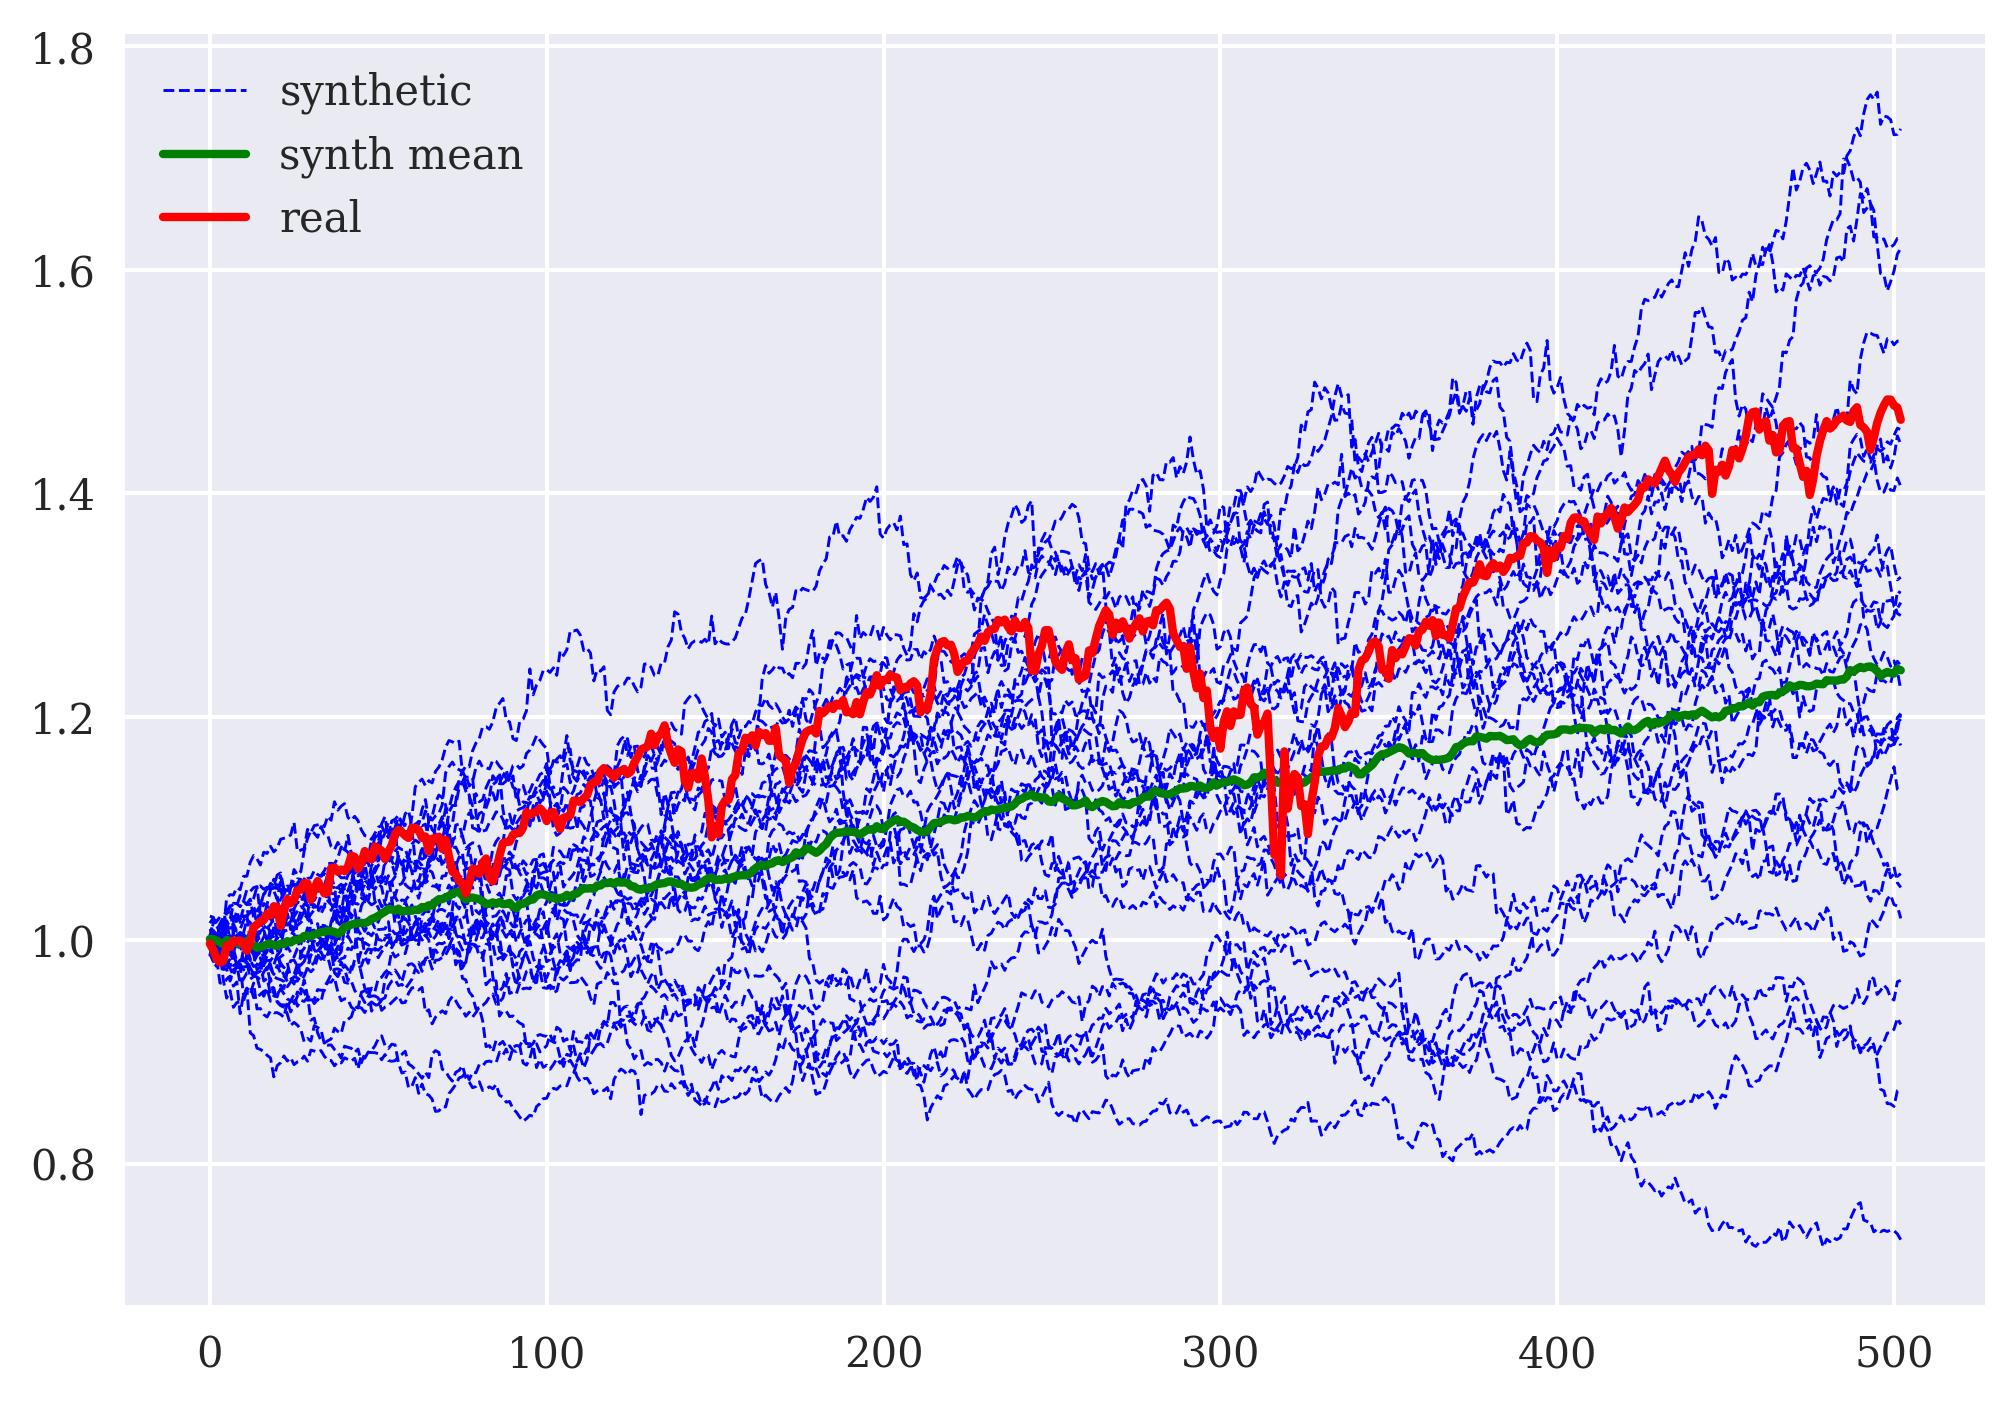

In [91]:
plot_cumulative(data, n_synth=N);

### Kolmogorov-Smirnov Test

In [92]:
synth_cols = [c for c in data.columns if c.startswith('synth')]
pvals = ks_test_batch(data['real'].values, data[synth_cols])
pvals.round(4)

array([0.9046, 0.2953, 0.6164, 0.9366, 0.4173, 0.0138, 0.0506, 0.2008,
       0.9613, 0.0599, 0.3329, 0.4173, 0.9046, 0.5639, 0.4638, 0.6696,
       0.5128, 0.1315, 0.2608, 0.7736, 0.2953, 0.5128, 0.8219, 0.866 ,
       0.3736])

In [93]:
f'KS pass rate: {pass_rate(pvals):.0%}'

'KS pass rate: 96%'

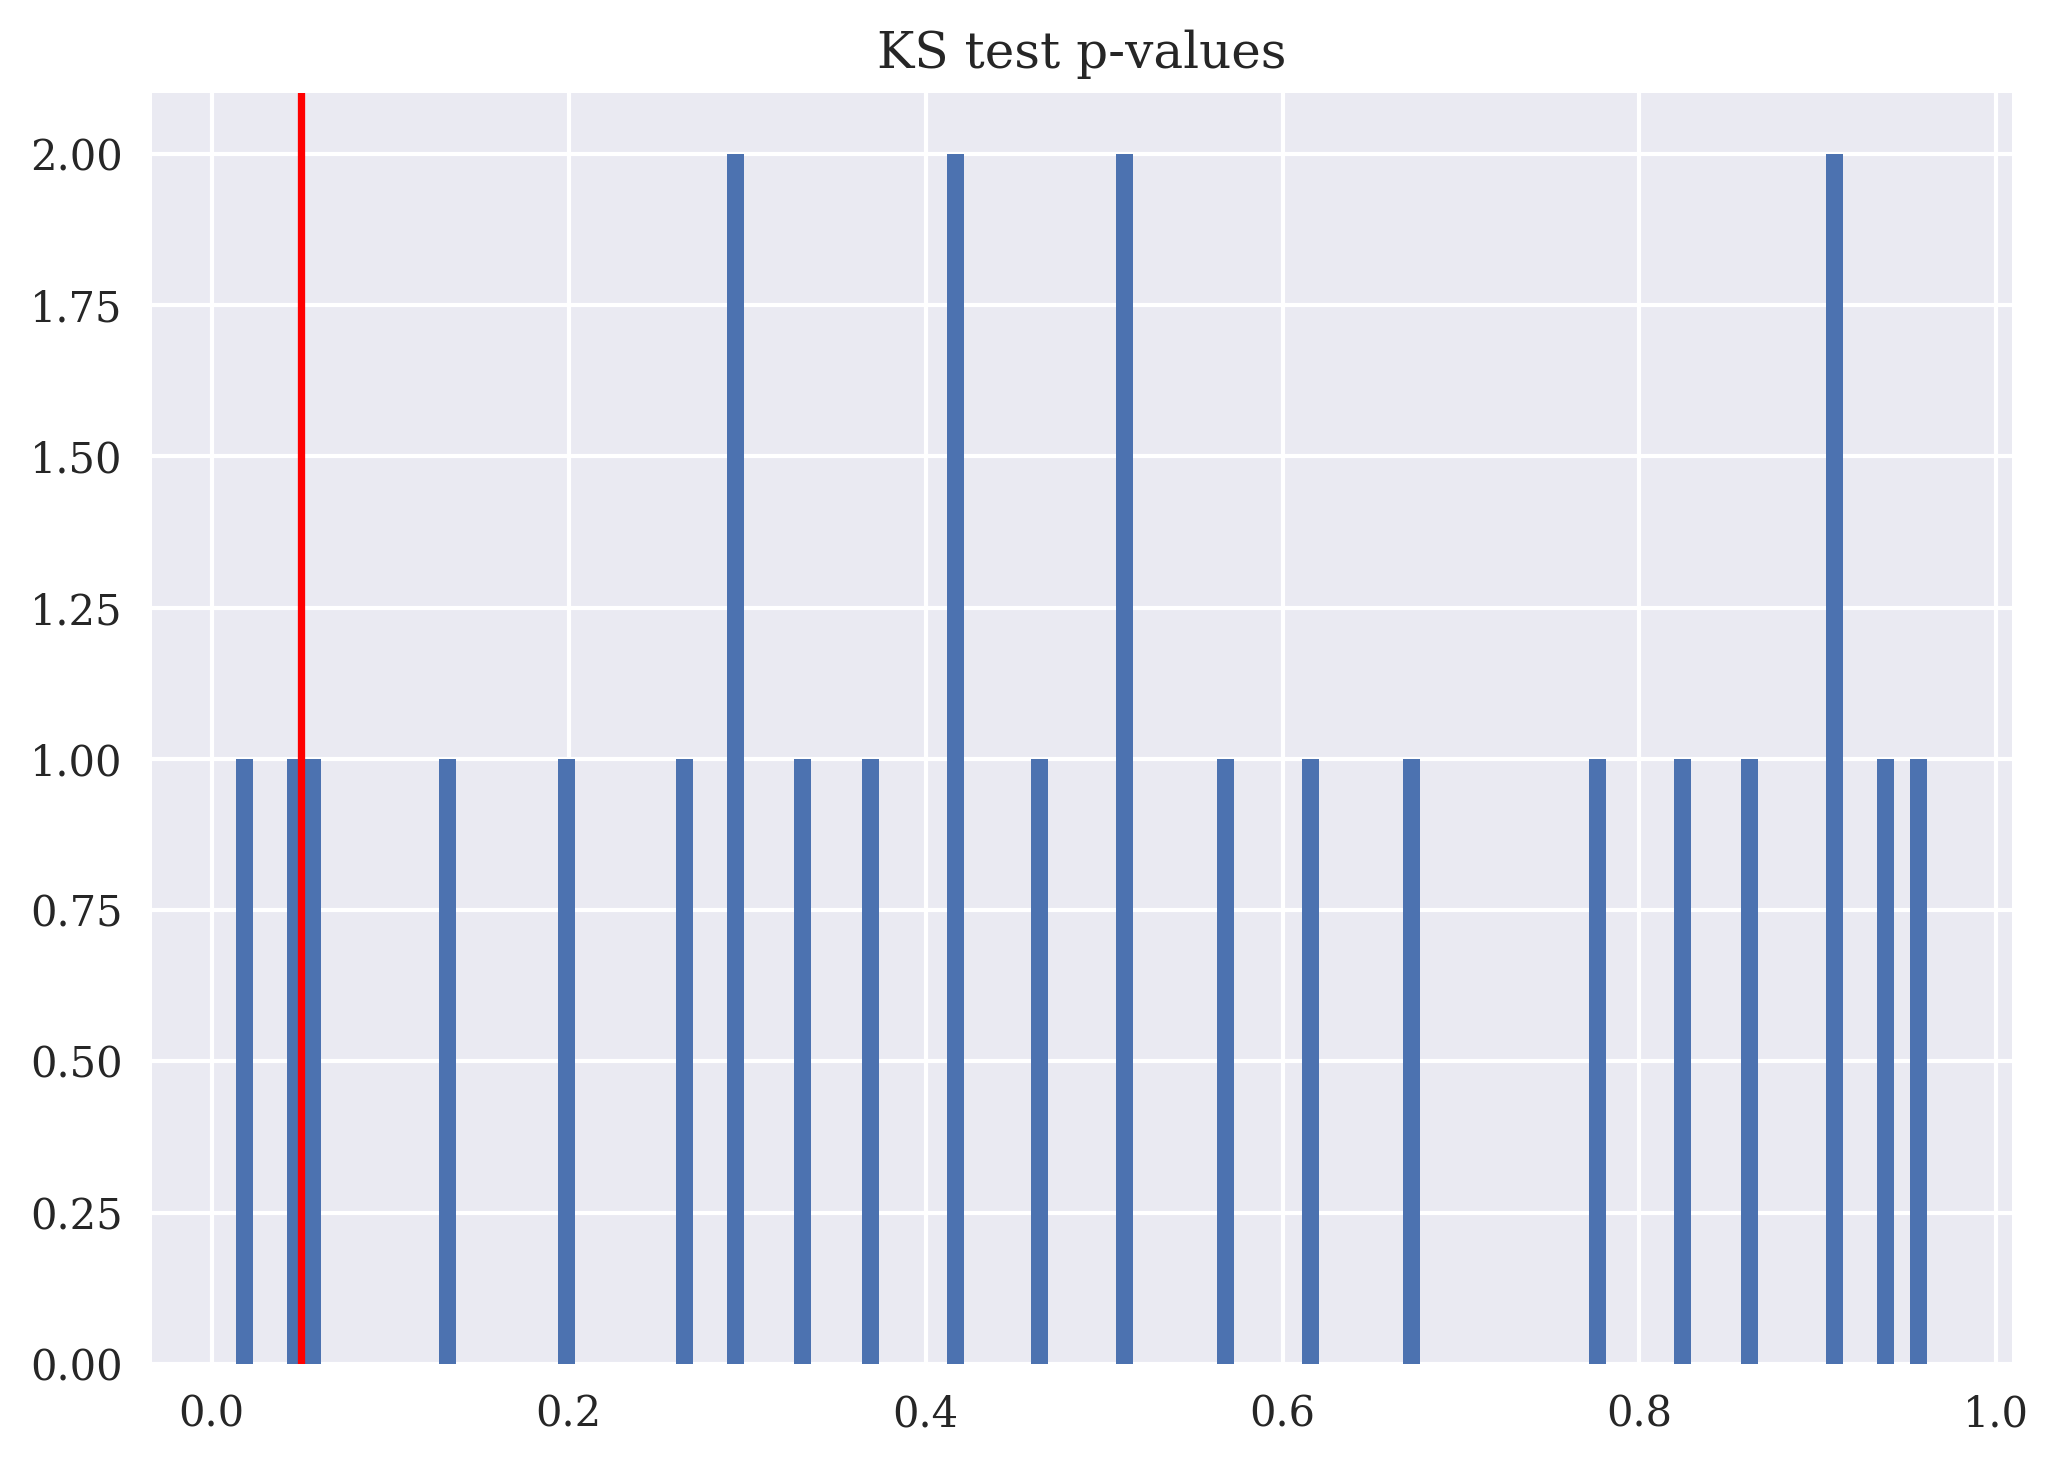

In [94]:
plot_pvalue_histogram(pvals);

<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>